# Python ARC Code Visualization for `a/des`

这个 notebook 用于可视化 `/home/lixinyu/snap/a/des` 目录下的 ARC 生成代码。

- 在“路径与运行参数”单元格中修改 `TARGET_ROOT`，可以传入任意子文件夹路径，例如 `/home/lixinyu/snap/a/des/seed1315637744`。
- 如果传入的 seed 文件夹本身没有 `.py`，会自动尝试解析到对应代码目录，例如 `/home/lixinyu/snap/a/des/code/combo_new/seed1315637744`。
- 每个 `.py` 文件调用 `generate_input()` 生成输入，再调用 `main(input)` 生成输出。
- 可视化形式仿照 `/home/lixinyu/snap/a/fable/visualize_seed1787762089_work.ipynb`：ARC 0-9 标准颜色、输入/输出并排、显示网格尺寸。
- `a/des` 中 `.py` 文件数量很多，建议先保持 `MAX_FILES` 为较小值预览，再按需调整 `TARGET_ROOT` 或 `MAX_FILES`。


In [7]:
from __future__ import annotations

import hashlib
import importlib.util
import inspect
import random
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display
from matplotlib.colors import BoundaryNorm, ListedColormap

ARC_COLORS = [
    "#000000",
    "#0074D9",
    "#FF4136",
    "#2ECC40",
    "#FFDC00",
    "#AAAAAA",
    "#F012BE",
    "#FF851B",
    "#7FDBFF",
    "#870C25",
]
ARC_CMAP = ListedColormap(ARC_COLORS)
ARC_NORM = BoundaryNorm(np.arange(-0.5, 10.5, 1), ARC_CMAP.N)


In [8]:
# 路径与运行参数：只改这个单元格即可切换可视化目标。
# 可以直接填 seed 子文件夹；如果该目录没有 .py，会自动查找对应的 code/.../seed 代码目录。
TARGET_ROOT = Path("/home/lixinyu/snap/a/des/seed1315637744")

DES_ROOT = Path("/home/lixinyu/snap/a/des")
VISUALIZATION_SEED = 0
EXAMPLES_PER_FILE = 4
MAX_FILES = 20  # 设为 None 会可视化全部匹配文件
EXCLUDE_DIR_NAMES = {"__pycache__", ".ipynb_checkpoints", "_codegen_logs"}


In [9]:
CELL_SIZE_INCH = 0.1
LEFT_MARGIN_INCH = 0.45
RIGHT_MARGIN_INCH = 0.45
TOP_MARGIN_INCH = 0.8
BOTTOM_MARGIN_INCH = 0.35
PAIR_GAP_INCH = 0.8


def as_grid(grid):
    arr = np.asarray(grid, dtype=int)
    if arr.ndim != 2:
        raise ValueError(f"Expected a 2D grid, got shape {arr.shape}")
    if arr.size == 0:
        raise ValueError("Grid is empty.")
    return arr


def _grid_extent_inch(grid):
    arr = as_grid(grid)
    rows, cols = arr.shape
    return cols * CELL_SIZE_INCH, rows * CELL_SIZE_INCH


def draw_arc_grid(ax, grid, title=""):
    arr = np.asarray(as_grid(grid), dtype=int).copy()
    ax.imshow(arr, cmap=ARC_CMAP, norm=ARC_NORM, interpolation="nearest")
    ax.set_title(f"{title}\n{arr.shape[0]}x{arr.shape[1]}", fontsize=11)
    ax.set_xticks(np.arange(-0.5, arr.shape[1], 1), minor=True)
    ax.set_yticks(np.arange(-0.5, arr.shape[0], 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=0.8)
    ax.tick_params(which="both", bottom=False, left=False, labelbottom=False, labelleft=False)
    ax.set_aspect("equal")


def _add_grid_axes(fig, grid, x_inch, y_inch, fig_w, fig_h, max_rows, title=""):
    arr = as_grid(grid)
    rows, cols = arr.shape
    width_inch = cols * CELL_SIZE_INCH
    height_inch = rows * CELL_SIZE_INCH
    vertical_offset = (max_rows - rows) * CELL_SIZE_INCH / 2

    ax = fig.add_axes([
        x_inch / fig_w,
        (y_inch + vertical_offset) / fig_h,
        width_inch / fig_w,
        height_inch / fig_h,
    ])
    draw_arc_grid(ax, arr, title=title)
    return ax


def show_grid_pair(input_grid, output_grid=None, title=""):
    input_arr = as_grid(input_grid)
    input_w, input_h = _grid_extent_inch(input_arr)

    if output_grid is None:
        fig_w = LEFT_MARGIN_INCH + input_w + RIGHT_MARGIN_INCH
        fig_h = TOP_MARGIN_INCH + input_h + BOTTOM_MARGIN_INCH
        fig = plt.figure(figsize=(fig_w, fig_h))
        _add_grid_axes(
            fig,
            input_arr,
            LEFT_MARGIN_INCH,
            BOTTOM_MARGIN_INCH,
            fig_w,
            fig_h,
            max_rows=input_arr.shape[0],
            title=title or "Grid",
        )
    else:
        output_arr = as_grid(output_grid)
        output_w, _ = _grid_extent_inch(output_arr)
        max_rows = max(input_arr.shape[0], output_arr.shape[0])
        fig_w = LEFT_MARGIN_INCH + input_w + PAIR_GAP_INCH + output_w + RIGHT_MARGIN_INCH
        fig_h = TOP_MARGIN_INCH + max_rows * CELL_SIZE_INCH + BOTTOM_MARGIN_INCH
        fig = plt.figure(figsize=(fig_w, fig_h))
        _add_grid_axes(
            fig,
            input_arr,
            LEFT_MARGIN_INCH,
            BOTTOM_MARGIN_INCH,
            fig_w,
            fig_h,
            max_rows=max_rows,
            title=f"{title} Input".strip(),
        )
        _add_grid_axes(
            fig,
            output_arr,
            LEFT_MARGIN_INCH + input_w + PAIR_GAP_INCH,
            BOTTOM_MARGIN_INCH,
            fig_w,
            fig_h,
            max_rows=max_rows,
            title=f"{title} Output".strip(),
        )

    plt.show()


In [10]:
def _path_sort_key(path: Path, root: Path):
    parts = path.relative_to(root).with_suffix("").parts
    key = []
    for part in parts:
        key.append((0, int(part)) if part.isdigit() else (1, part))
    return key


def _is_excluded(path: Path, root: Path):
    relative_parts = path.relative_to(root).parts
    return any(part in EXCLUDE_DIR_NAMES for part in relative_parts)


def _has_visualizable_py(root: Path):
    if not root.exists() or not root.is_dir():
        return False
    return any(
        path.name != "__init__.py" and not _is_excluded(path, root)
        for path in root.rglob("*.py")
    )


def resolve_code_root(root_path=None):
    """Resolve user-facing seed folders to their generated-code folders when needed."""
    requested = Path(root_path or TARGET_ROOT).expanduser().resolve()
    if not requested.exists():
        raise FileNotFoundError(requested)
    if requested.is_file():
        return requested.parent
    if _has_visualizable_py(requested):
        return requested

    des_root = Path(DES_ROOT).expanduser().resolve()
    seed_name = requested.name
    candidates = [
        des_root / "code" / "combo_new" / seed_name,
        des_root / "code" / "eval" / seed_name,
    ]
    code_root = des_root / "code"
    if code_root.exists():
        candidates.extend(
            path for path in code_root.rglob(seed_name) if path.is_dir() and path not in candidates
        )

    for candidate in candidates:
        if _has_visualizable_py(candidate):
            display(Markdown(
                f"Resolved `{requested}` to code directory `{candidate.resolve()}`."
            ))
            return candidate.resolve()

    return requested


def discover_code_files(root_path=None):
    root = resolve_code_root(root_path)
    return sorted(
        (
            path
            for path in root.rglob("*.py")
            if path.name != "__init__.py" and not _is_excluded(path, root)
        ),
        key=lambda path: _path_sort_key(path, root),
    )


def load_module_from_path(module_path):
    module_path = Path(module_path).expanduser().resolve()
    module_key = hashlib.sha1(str(module_path).encode("utf-8")).hexdigest()[:12]
    module_name = f"des_viz_{module_path.stem}_{module_key}"
    spec = importlib.util.spec_from_file_location(module_name, module_path)
    if spec is None or spec.loader is None:
        raise ImportError(f"Could not load module spec for {module_path}")
    module = importlib.util.module_from_spec(spec)
    # dataclass 等运行时会通过 sys.modules 查询当前模块；先注册再 exec 更稳妥。
    sys.modules[module_name] = module
    spec.loader.exec_module(module)
    return module


def supports_visualization(module):
    return callable(getattr(module, "generate_input", None)) and callable(getattr(module, "main", None))


def call_generate_input(generate_input_fn, seed=0):
    signature = inspect.signature(generate_input_fn)
    required = [
        param
        for param in signature.parameters.values()
        if param.kind in (inspect.Parameter.POSITIONAL_ONLY, inspect.Parameter.POSITIONAL_OR_KEYWORD)
        and param.default is inspect.Signature.empty
    ]
    random.seed(seed)
    np.random.seed(seed)
    if not required:
        return generate_input_fn()
    if len(required) == 1:
        param = required[0]
        if param.kind is inspect.Parameter.POSITIONAL_ONLY:
            return generate_input_fn(seed)
        return generate_input_fn(**{param.name: seed})
    raise TypeError(f"Unsupported generate_input signature: {signature}")


def generate_io_pair(module, seed=0):
    input_grid = as_grid(call_generate_input(module.generate_input, seed=seed))
    output_grid = as_grid(module.main(input_grid.copy()))
    return input_grid, output_grid


In [11]:
def visualize_code_files(code_files, *, root=None, seed=0, num_examples=4):
    root = Path(root or TARGET_ROOT).expanduser().resolve()
    paths = [Path(path).expanduser().resolve() for path in code_files]

    visualized = 0
    pairs_visualized = 0
    skipped = []
    errors = []

    for code_file in paths:
        rel_path = code_file.relative_to(root)
        try:
            module = load_module_from_path(code_file)
            if not supports_visualization(module):
                skipped.append((rel_path, "missing generate_input() or main()"))
                continue

            display(Markdown(f"## `{rel_path}`"))
            for example_idx in range(num_examples):
                example_seed = seed + example_idx
                input_grid, output_grid = generate_io_pair(module, seed=example_seed)
                show_grid_pair(
                    input_grid,
                    output_grid,
                    title=f"{rel_path} Example {example_idx + 1}",
                )
                pairs_visualized += 1
            visualized += 1
        except Exception as exc:
            errors.append((rel_path, exc))
            display(Markdown(f"**Error in `{rel_path}`:** `{type(exc).__name__}: {exc}`"))

    display(Markdown(
        "## Summary\n"
        f"- Root: `{root}`\n"
        f"- Scanned files: {len(paths)}\n"
        f"- Visualized files: {visualized}\n"
        f"- Examples per file: {num_examples}\n"
        f"- Visualized pairs: {pairs_visualized}\n"
        f"- Skipped files: {len(skipped)}\n"
        f"- Error files: {len(errors)}"
    ))

    if skipped:
        display(Markdown(
            "### Skipped\n" + "\n".join(f"- `{path}`: {reason}" for path, reason in skipped)
        ))
    if errors:
        display(Markdown(
            "### Errors\n" + "\n".join(
                f"- `{path}`: `{type(exc).__name__}: {exc}`" for path, exc in errors
            )
        ))

    return {
        "root": root,
        "scanned": len(paths),
        "visualized": visualized,
        "examples_per_file": num_examples,
        "pairs_visualized": pairs_visualized,
        "skipped": skipped,
        "errors": errors,
    }


def visualize_code_path(root_path=None, seed=0, max_files=None, num_examples=4):
    root = resolve_code_root(root_path)
    code_files = discover_code_files(root)
    if max_files is not None:
        code_files = code_files[:max_files]
    return visualize_code_files(code_files, root=root, seed=seed, num_examples=num_examples)


## 可视化当前 `TARGET_ROOT`

运行前先在“路径与运行参数”单元格中设置目标路径。可以传入 seed 子文件夹，例如 `/home/lixinyu/snap/a/des/seed1315637744`；如果这个目录没有 `.py`，会自动解析到对应的 `code/.../seed1315637744` 代码目录。


Resolved `/home/lixinyu/snap/a/des/seed1315637744` to code directory `/home/lixinyu/snap/a/des/code/combo_new/seed1315637744`.

## `1/1.py`

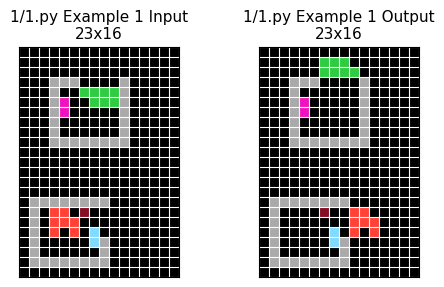

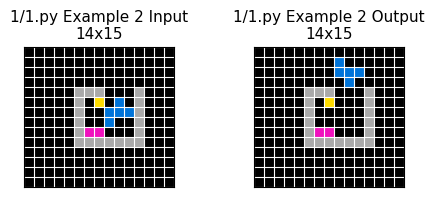

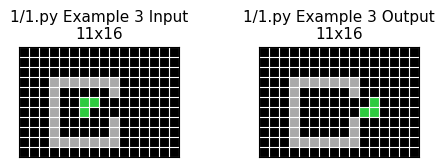

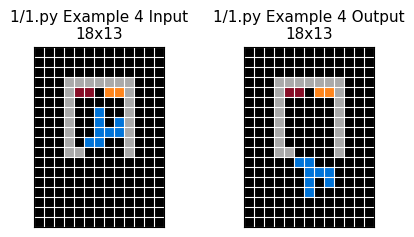

## `1/2.py`

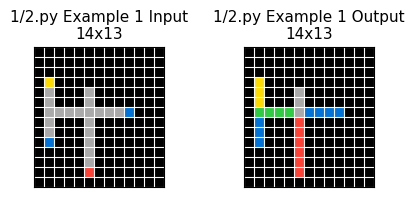

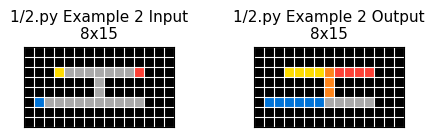

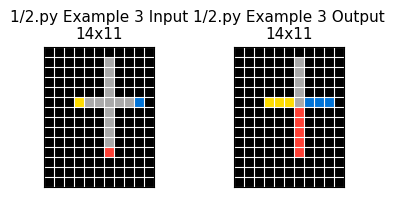

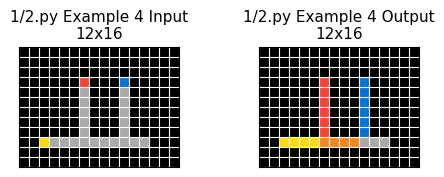

## `1/3.py`

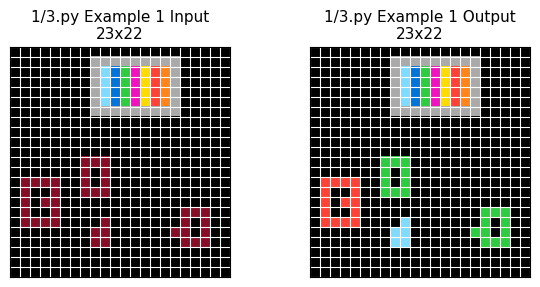

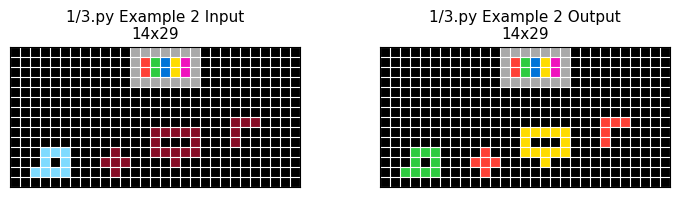

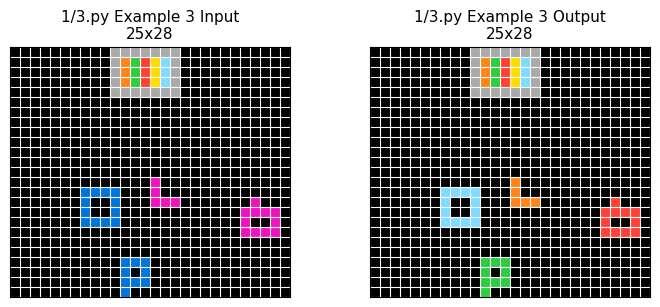

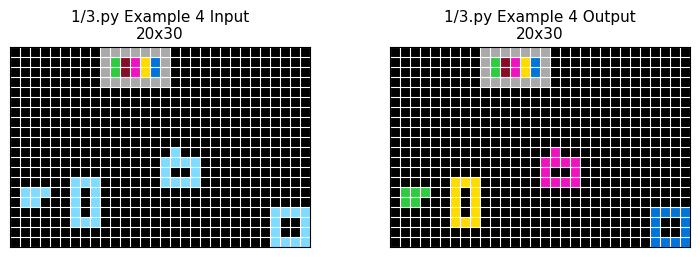

## `1/4.py`

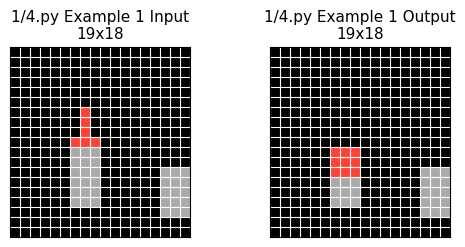

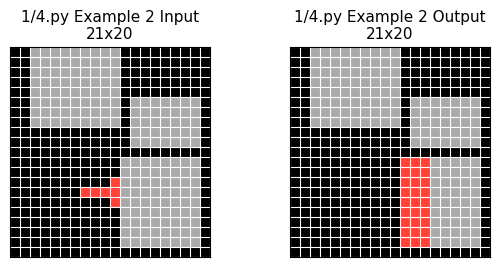

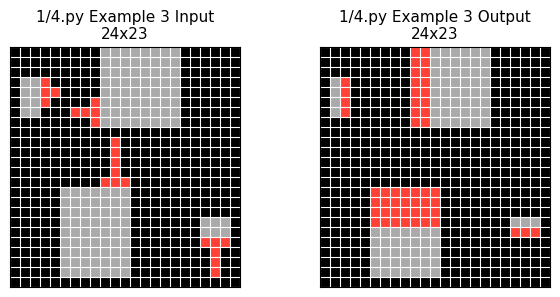

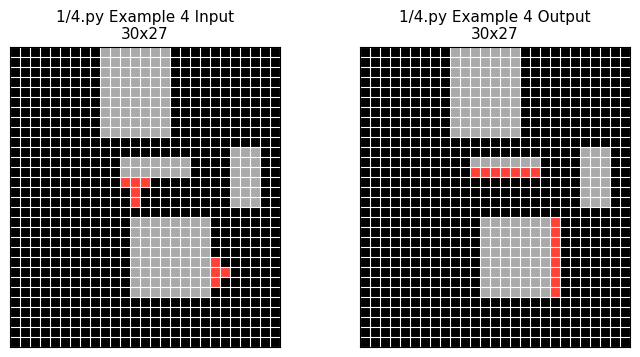

## `1/5.py`

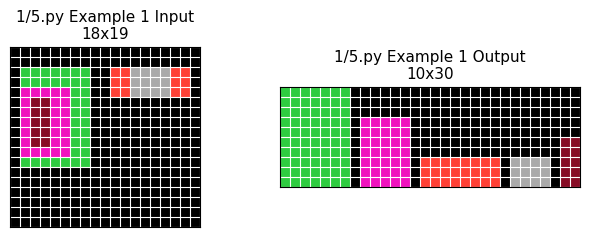

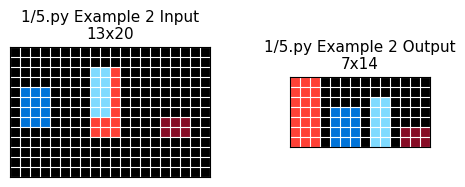

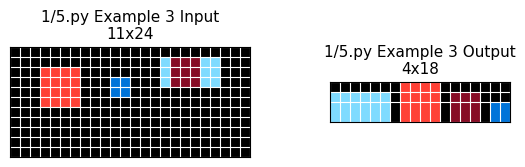

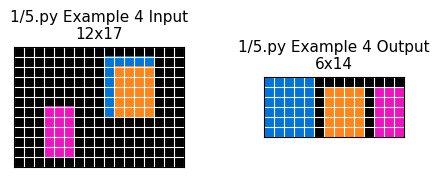

## `1/6.py`

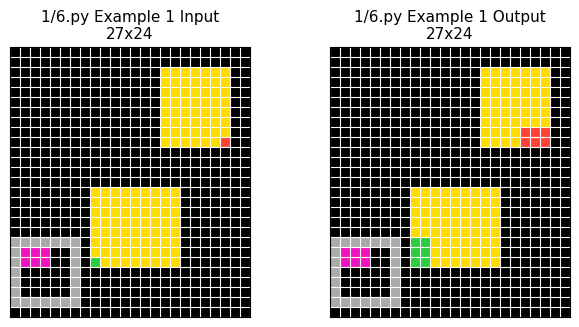

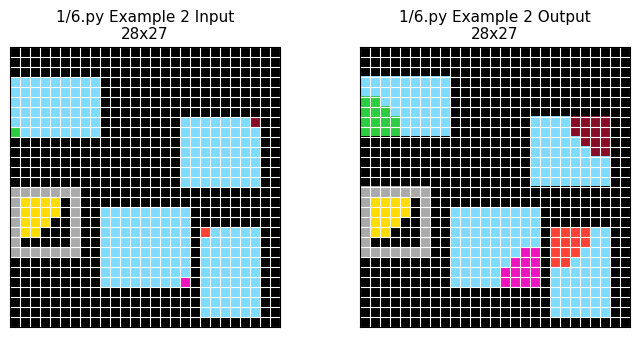

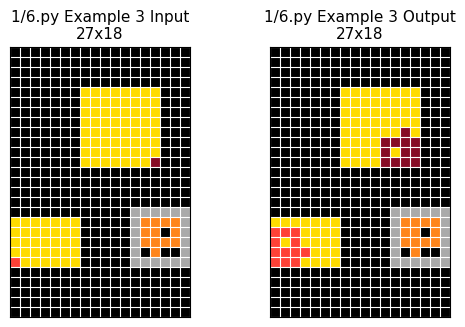

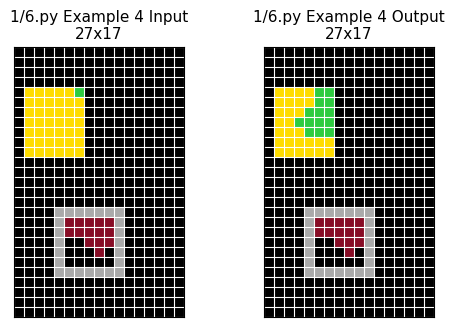

## `1/7.py`

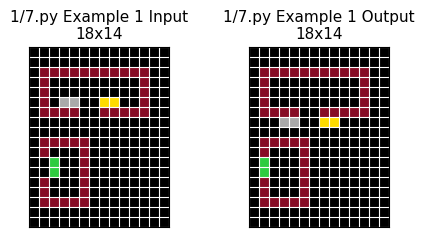

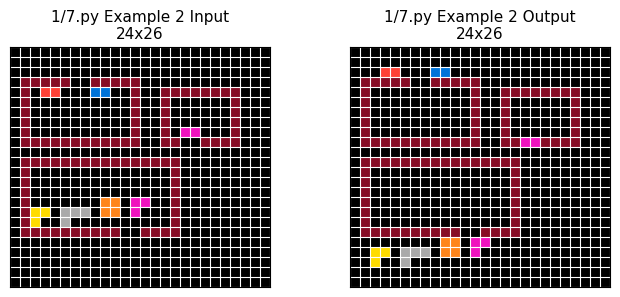

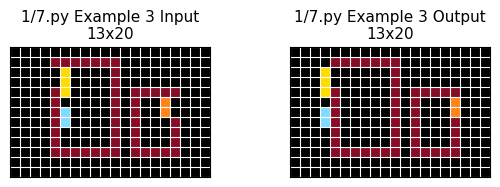

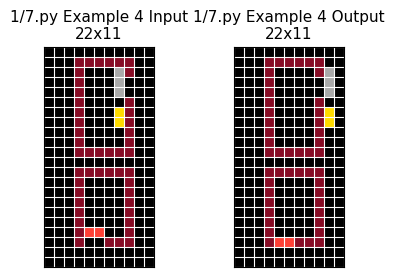

## `1/8.py`

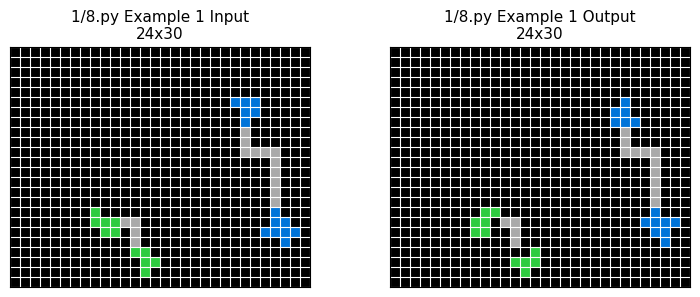

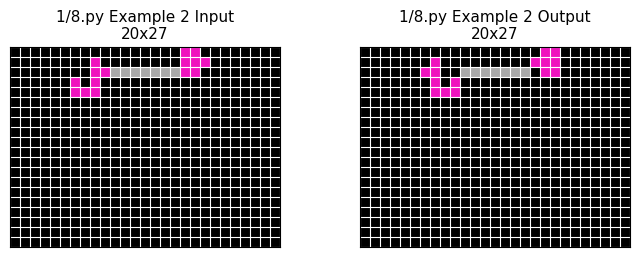

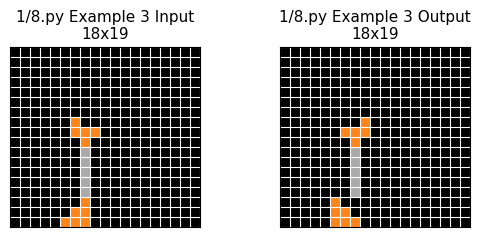

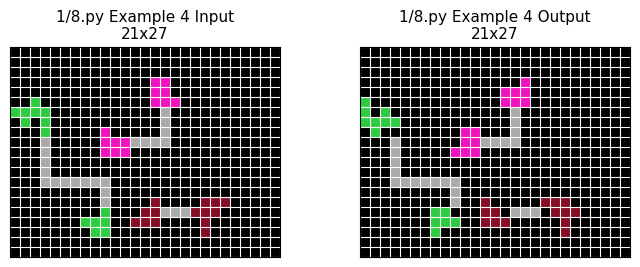

## `2/1.py`

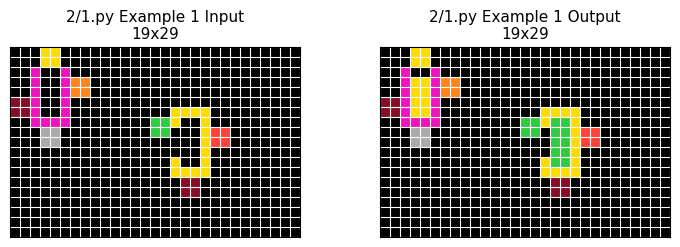

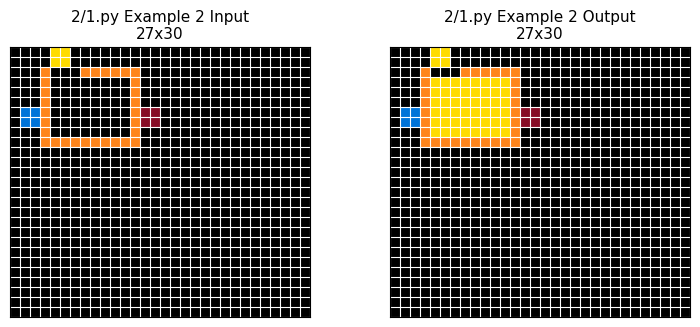

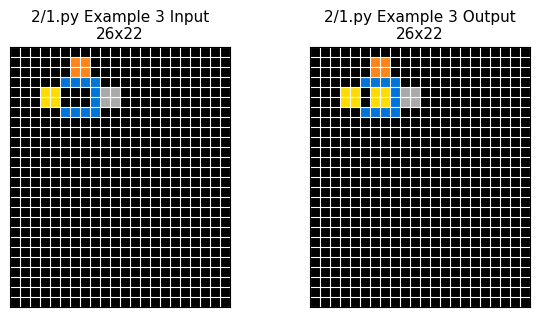

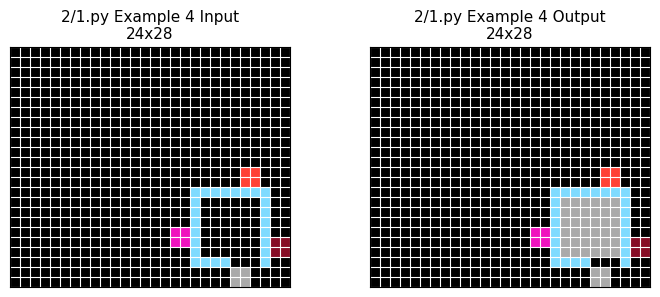

## `2/2.py`

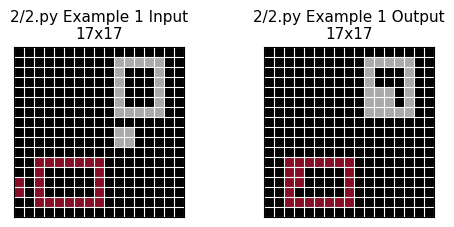

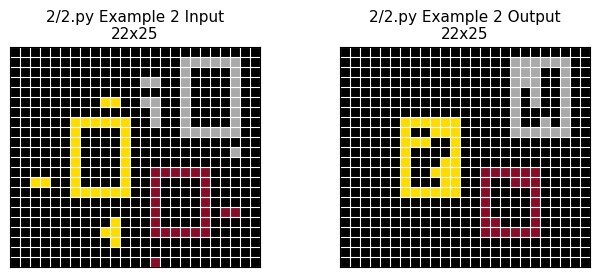

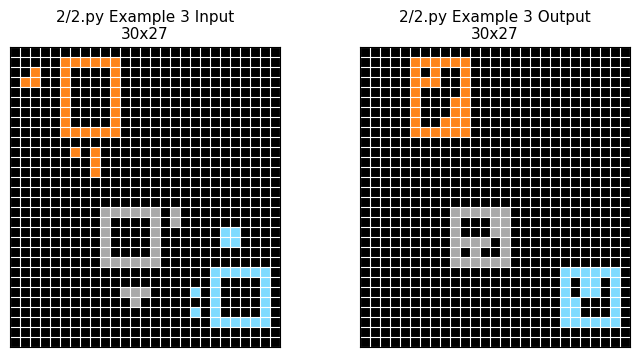

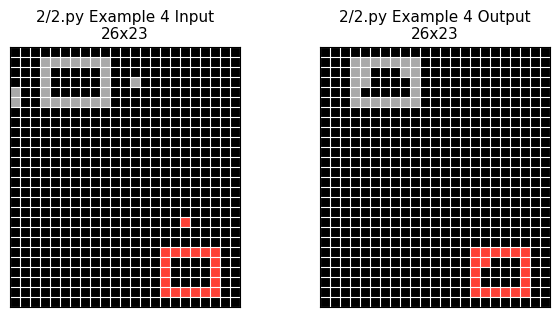

## `2/3.py`

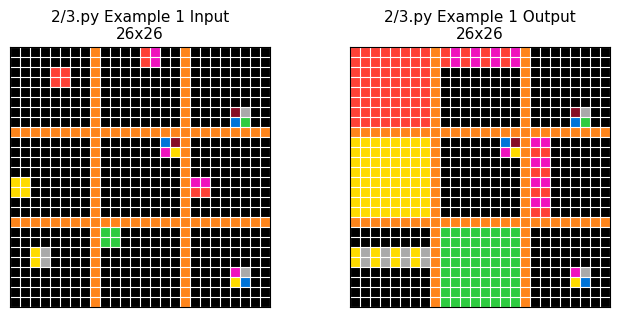

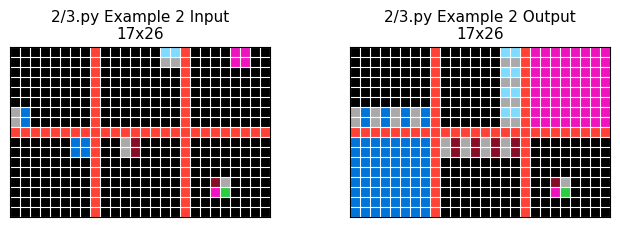

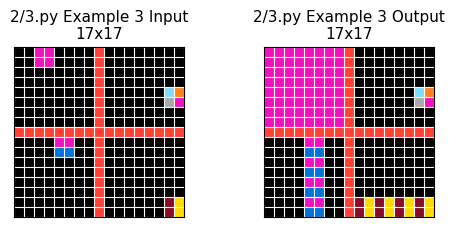

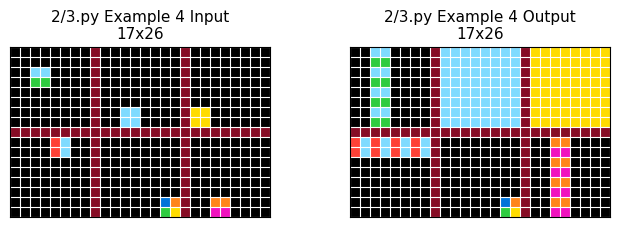

## `2/4.py`

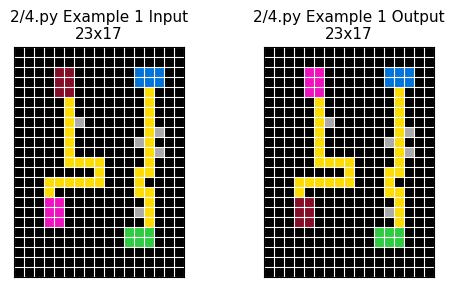

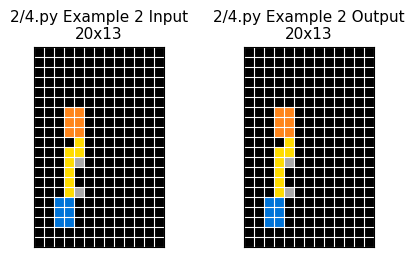

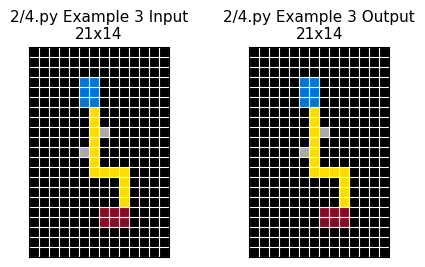

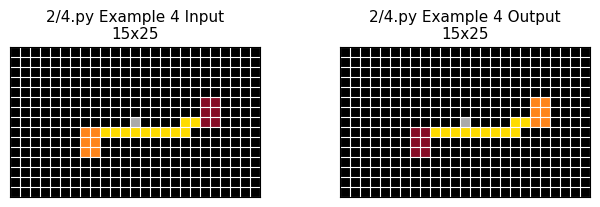

## `2/5.py`

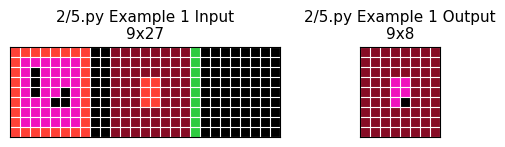

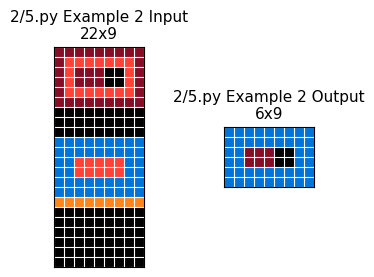

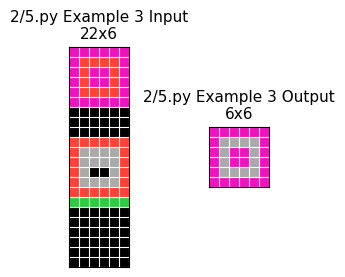

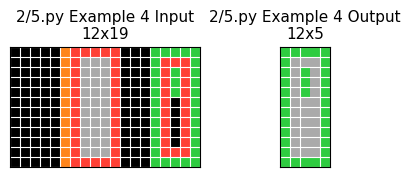

## `2/6.py`

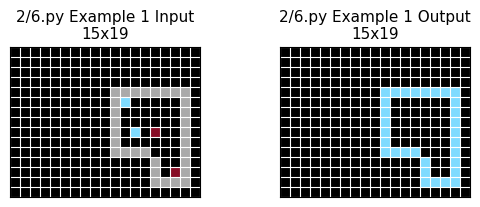

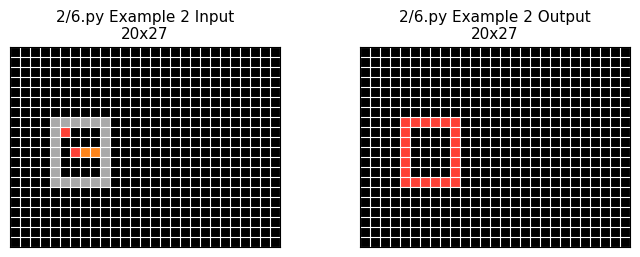

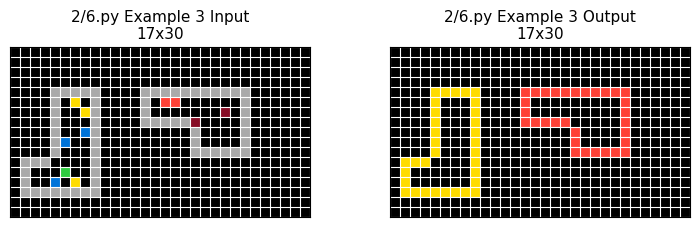

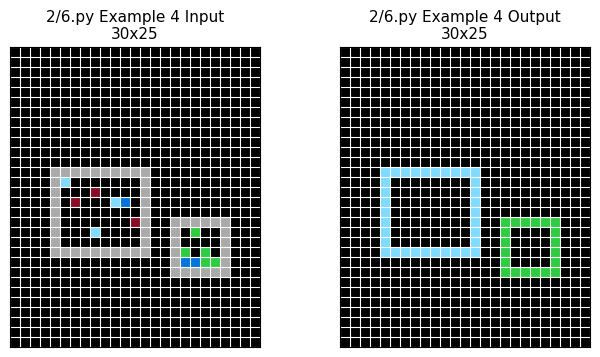

## `2/7.py`

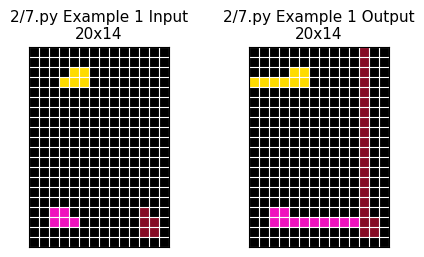

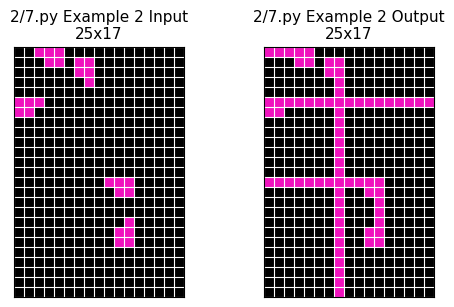

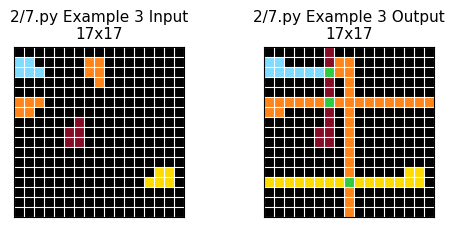

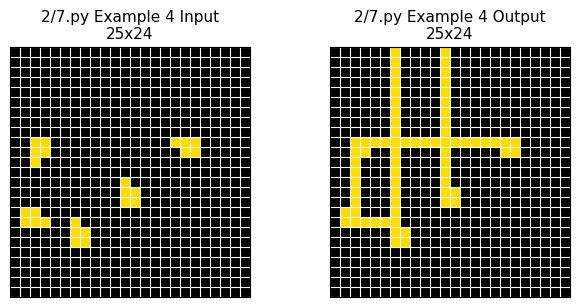

## `2/8.py`

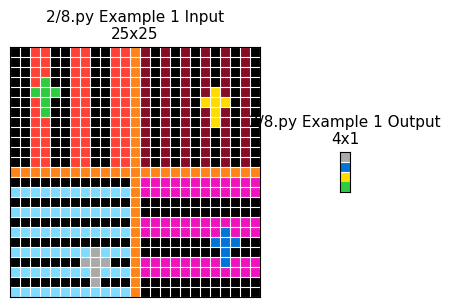

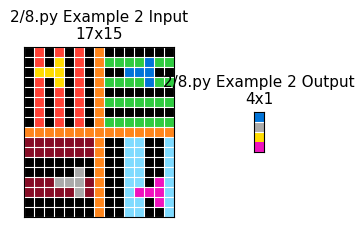

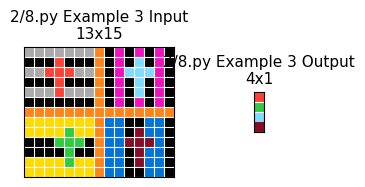

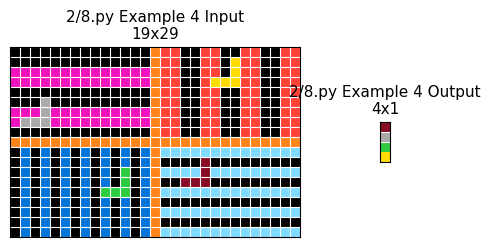

## `3/1.py`

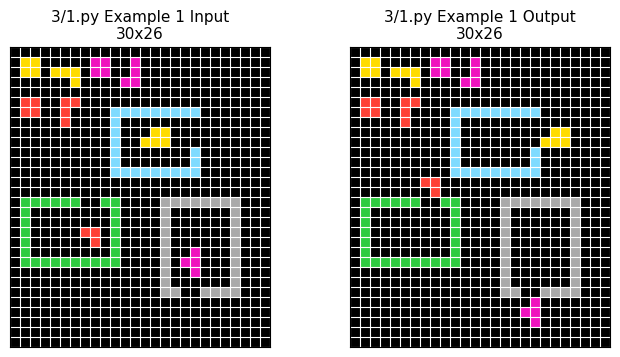

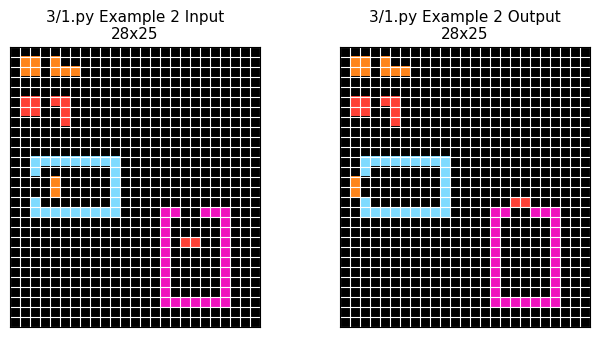

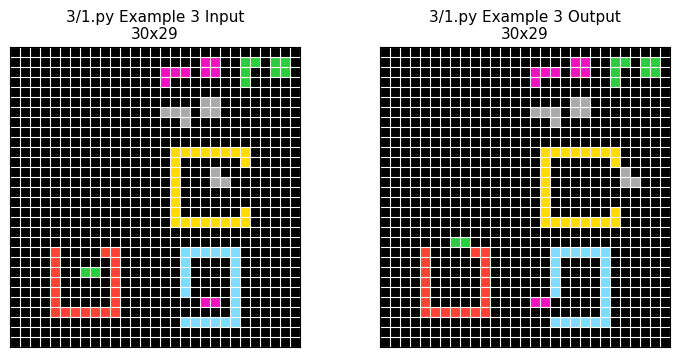

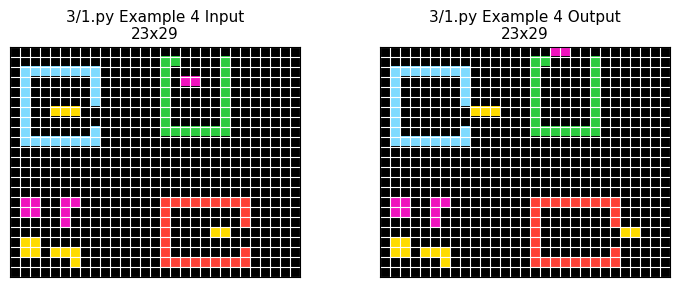

## `3/2.py`

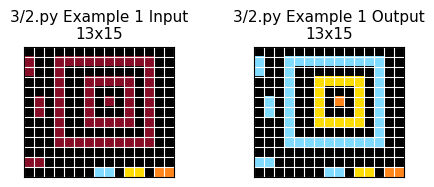

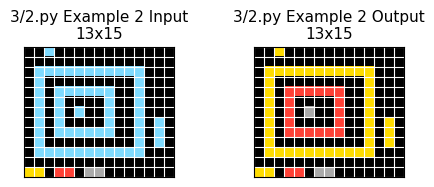

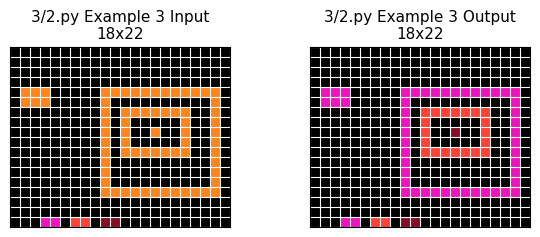

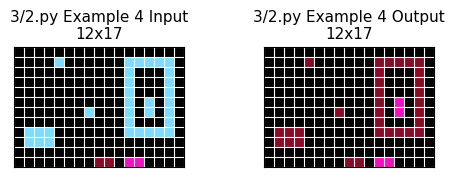

## `3/3.py`

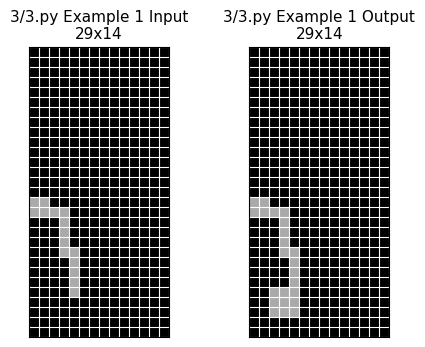

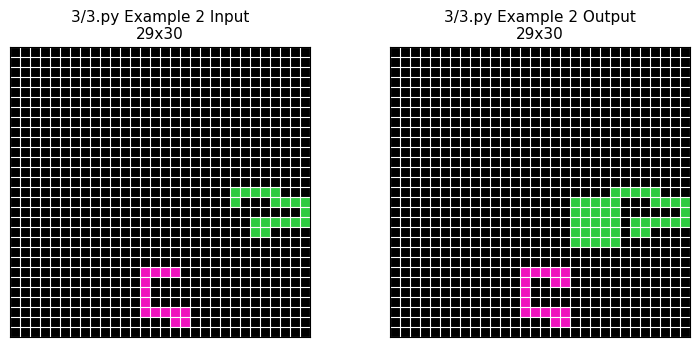

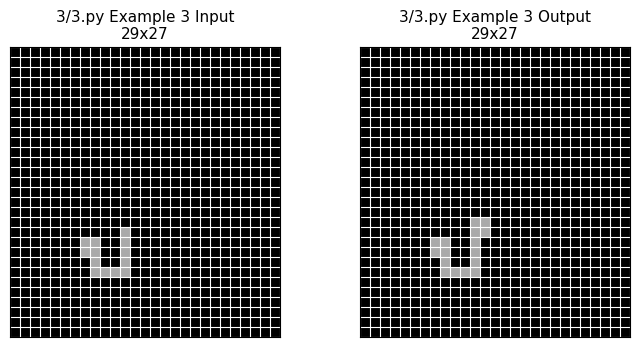

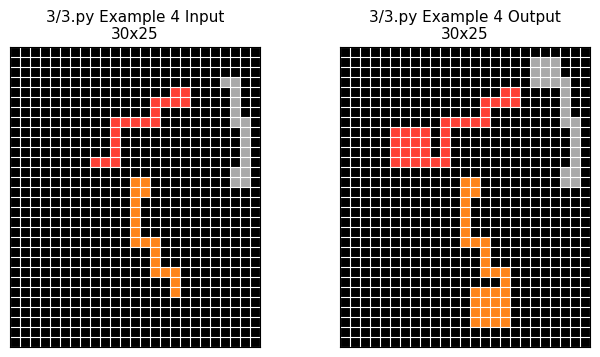

## `3/4.py`

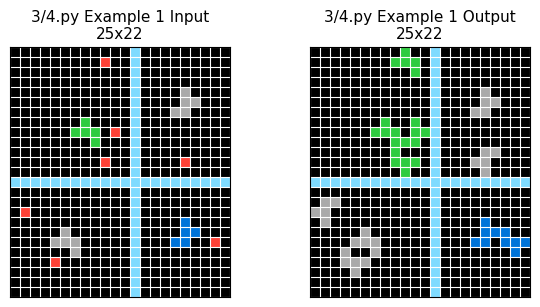

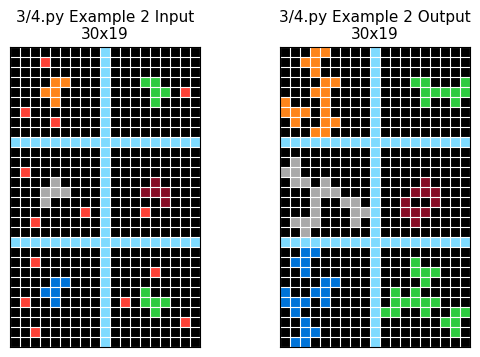

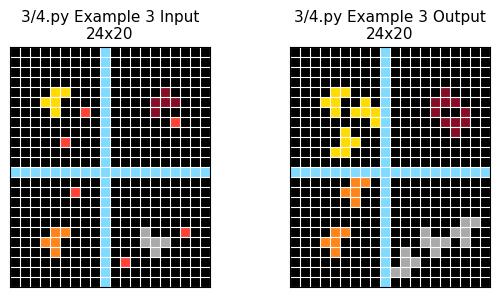

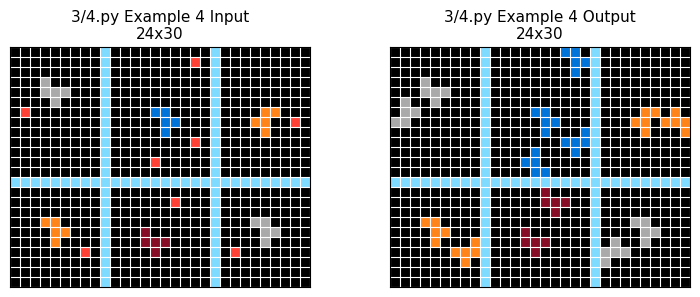

## Summary
- Root: `/home/lixinyu/snap/a/des/code/combo_new/seed1315637744`
- Scanned files: 20
- Visualized files: 20
- Examples per file: 4
- Visualized pairs: 80
- Skipped files: 0
- Error files: 0

{'root': PosixPath('/home/lixinyu/snap/a/des/code/combo_new/seed1315637744'),
 'scanned': 20,
 'visualized': 20,
 'examples_per_file': 4,
 'pairs_visualized': 80,
 'skipped': [],
 'errors': []}

In [12]:
result = visualize_code_path(
    TARGET_ROOT,
    seed=VISUALIZATION_SEED,
    max_files=MAX_FILES,
    num_examples=EXAMPLES_PER_FILE,
)
result
